<a href="https://colab.research.google.com/github/Prathamesh-kadam/LSST-Alert-Broker-/blob/main/PittGoogle.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
 !pip install -q pittgoogle-client fink-client antares-client "antares-client[subscriptions]"

In [2]:
!pip install -U "marshmallow>=3.6,<4.0"

In [3]:
import pittgoogle, fink_client, antares_client
print("ok")

ok


/usr/local/lib/python3.13/dist-packages/antares_client/stream.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [4]:
import os
from google.colab import auth
auth.authenticate_user()

os.environ["GOOGLE_CLOUD_PROJECT"] = "<your-project-id>"

In [17]:
from google.colab import files
files.upload()   # pick your service-account JSON key
os.environ["GOOGLE_APPLICATION_CREDENTIALS"] = "/content/<your-key-file>.json"

KeyboardInterrupt: 

In [18]:
from google.colab import userdata
fink_user = userdata.get("FINK_USERNAME")
fink_group = userdata.get("FINK_GROUP_ID")

SecretNotFoundError: Secret FINK_USERNAME does not exist.

In [21]:
!gcloud services list --enabled --project=galvanized-case-513605-v3 | grep -E "bigquery|pubsub|storage"

bigquery.googleapis.com              BigQuery API
bigqueryconnection.googleapis.com    BigQuery Connection API
bigquerydatapolicy.googleapis.com    BigQuery Data Policy API
bigquerydatatransfer.googleapis.com  BigQuery Data Transfer API
bigquerymigration.googleapis.com     BigQuery Migration API
bigqueryreservation.googleapis.com   BigQuery Reservation API
bigquerystorage.googleapis.com       BigQuery Storage API
pubsub.googleapis.com                Cloud Pub/Sub API
storage-api.googleapis.com           Google Cloud Storage JSON API
storage-component.googleapis.com     Cloud Storage
storage.googleapis.com               Cloud Storage API


In [20]:
!gcloud services enable pubsub.googleapis.com --project=galvanized-case-513605-v3

Operation "operations/acf.p2-467959761799-236139d4-5b14-40da-926e-232711a363d6" finished successfully.


In [16]:
from google.colab import auth
auth.authenticate_user()

!gcloud projects list

PROJECT_ID                 NAME              PROJECT_NUMBER  ENVIRONMENT
galvanized-case-513605-v3  PittGoogle IUCAA  467959761799


In [10]:
from google.colab import auth
auth.authenticate_user()

!gcloud projects list

PROJECT_ID                 NAME              PROJECT_NUMBER  ENVIRONMENT
galvanized-case-513605-v3  PittGoogle IUCAA  467959761799


In [23]:
import os
from google.colab import files

uploaded = files.upload()          # pick the NEW .json file
key_path = "/content/" + list(uploaded.keys())[0]

os.environ["GOOGLE_APPLICATION_CREDENTIALS"] = key_path
os.environ["GOOGLE_CLOUD_PROJECT"] = "galvanized-case-513605-v3"

Saving galvanized-case-513605-v3-fc4117278ce4.json to galvanized-case-513605-v3-fc4117278ce4.json


In [24]:
from google.cloud import bigquery

client = bigquery.Client(project="galvanized-case-513605-v3")
print([dict(r) for r in client.query("SELECT 1 AS test").result()])

[{'test': 1}]


I am starting the Gituhub file, Plot a light curve using BigQuery (~10 min)  sgared in the pdf, https://github.com/mwvgroup/pittgoogle-user-demos/blob/164f640da69412b008ab0553bf2e9832eced4519/bigquery/ssObjects.ipynb

In [33]:
import pittgoogle
import matplotlib.pyplot as plt

In [26]:
bqclient = pittgoogle.bigquery.Client() # load the BigQuery client

sql_query = f"""
SELECT
  diaSource.psfFlux,
  diaSource.psfFluxErr,
  ssSource.ssObjectId,
  diaSource.band,
  diaSource.midpointMjdTai,
  diaSource.reliability
FROM `pitt-alert-broker.lsst.alerts_v10_0`
WHERE ssSource.ssObjectId IS NOT NULL
ORDER BY ssSource.ssObjectId
LIMIT 500000
"""

results = bqclient.query(query=sql_query)
results

,psfFlux,psfFluxErr,ssObjectId,band,midpointMjdTai,reliability
0,7.322521e+05,1788.666382,20883249147424840,u,61144.064094,1.000000
1,6.200278e+06,3286.160400,20883249147424840,z,61144.066427,1.000000
2,7.015528e+05,1670.391235,20883249147424840,u,61145.128659,1.000000
3,8.341148e+05,1969.630005,20883249147424840,u,61143.059754,1.000000
4,8.340577e+05,2043.702026,20883249147424840,u,61143.059201,1.000000
...,...,...,...,...,...,...
485992,4.555677e+04,1534.975464,23700330444239416,y,61108.088795,1.000000
485993,4.571167e+04,488.377533,23700330444239416,z,61108.090689,1.000000
485994,2.659899e+04,331.930145,23700330444239416,g,61107.060740,0.999849
485995,5.254407e+04,487.507050,23700330444239416,i,61107.063055,1.000000


In [27]:
len(results["ssObjectId"].unique())

3568

In [28]:
def plot_lc(ssObjectId, ssObjects):
    photometry = ssObjects[ssObjects.ssObjectId == ssObjectId]

    fig, ax = plt.subplots(figsize=(10, 5))

    for b in photometry.band.unique():
        idx = photometry.band == b
        ax.errorbar(
            photometry.loc[idx].midpointMjdTai,
            photometry.loc[idx].psfFlux,
            yerr=photometry.loc[idx].psfFluxErr,
            fmt='o',
            label=b
        )

    ax.set_xlabel('midpointMjdTai')
    ax.set_ylabel('psfFlux [nJy]')
    ax.set_title(f'Light Curve — ssObjectId {ssObjectId}')
    ax.legend(title='Band')
    plt.tight_layout()
    plt.show()

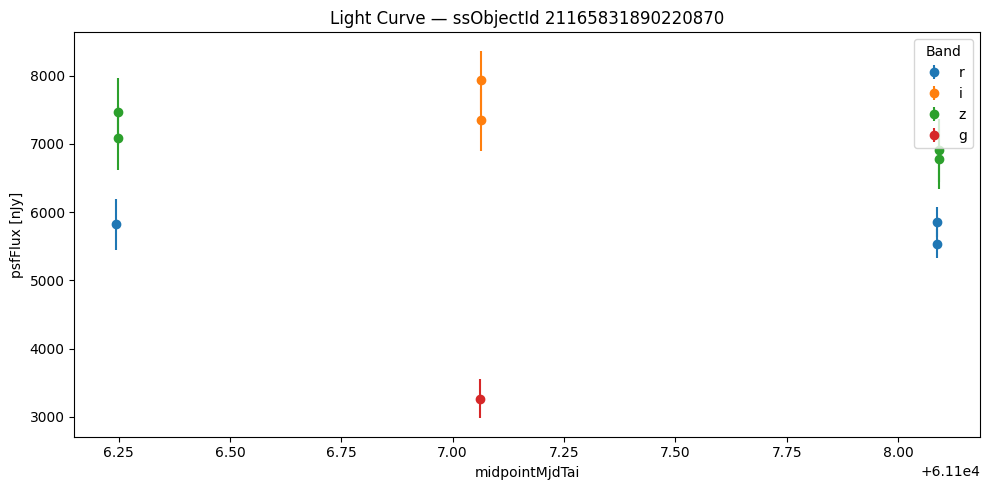

In [31]:
plot_lc(21165831890220870, results)

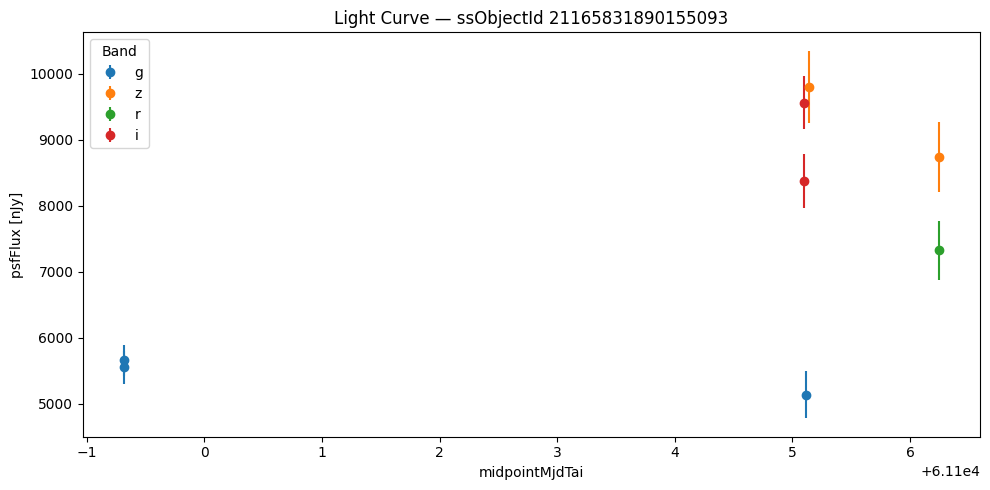

In [32]:
plot_lc(21165831890155093, results)

1. Check the Total Rows in the BigQuery Table directly (Without downloading data)

In [34]:
sql = """
SELECT COUNT(*) as total_rows
FROM `pitt-alert-broker.lsst.alerts_v10_0`
"""

df_count = client.query(sql).to_dataframe()
print("Total rows in database:", df_count['total_rows'].iloc[0])

Total rows in database: 10627243


# Access LSST Alert Data via BigQuery

The Pitt-Google Alert Broker's tabular alert and value-added alert data is stored in [BigQuery](https://docs.cloud.google.com/bigquery/docs/introduction). The dataset and tables names containing LSST data are outlined in our [data listings page](https://mwvgroup.github.io/pittgoogle-client/listings.html#id4).

## Table of Contents

- [Alert tables (overview)](#alert-tables)
- [Value-added tables (overview)](#value-added-tables)
- [SQL query examples](#sql-query-examples)

## Prerequisites

- Complete the [One-Time Setup](https://mwvgroup.github.io/pittgoogle-client/one-time-setup/index.html), specifically:
     - Install the pittgoogle-client package
     - Setup authentication to a Google Cloud project
     - Set environment variables
     - Enable the BigQuery API
     - You can skip the command-line tools

In [36]:
import pittgoogle

# define the Pitt-Google Alert Broker's GCP project name
pgb_project = "pitt-alert-broker"

The alert tables served by the Pitt-Google Alert Broker represent an archive of the `lsst-alerts` Pub/Sub stream. These tables preserve the structure of the original alert packets (excluding cutouts), including all nested and repeated fields defined in the versioned LSST alert schema. To improve query performance and reduce query costs, these tables are partitioned by the field: `kafkaPublishTimestamp` and clustered by the fields: `healpix9`, `healpix19`, and `healpix29`.

### Partitions

Partitioning an alert table by the `kafkaPublishTimestamp` field divides the table into daily segments, effectively reducing the number of bytes read by a query when a date (or date range) is specified.

### Clustering

The `healpix9`, `healpix19`, and `healpix29` fields represent the [HEALPix](https://healpix.sourceforge.io) spatial index of the diaSource at three commonly used resolutions ($N_{side} = 2^9$, $2^{19}$, and $2^{29}$). Clustering the alert tables by these fields sorts data within each partition by the HEALPix index, placing nearby sky regions physically close in storage. Depending on the search scale, queries can target coarse (order 9) or fine (order 29) spatial partitions.

The diagram below, obtained from Google's documentation on the [combination of clustered and partitioned tables](https://docs.cloud.google.com/bigquery/docs/clustered-tables#combine-clustered-partitioned-tables) demonstrates how more finely grained sorting is achieved using these methods.

![title](clustering-and-partitioning-tables.png)

The LSST alert schema v10_0 can be accessed [here](https://github.com/lsst/alert_packet/tree/main/python/lsst/alert/packet/schema/10/0) for your convenience. You can alternatively explore the schema of the `alerts_v10_0` table in the cell below:

In [37]:
alerts_tbl = pittgoogle.bigquery.Table(name="alerts_v10_0", dataset="lsst", projectid=pgb_project)
alerts_tbl.schema

,name,type,mode,description
0,diaSourceId,INTEGER,REQUIRED,Identifier of the triggering DiaSource
1,observation_reason,STRING,NULLABLE,Scheduler reason for the image containing this...
2,target_name,STRING,NULLABLE,Scheduler target for the image containing this...
3,diaSource,RECORD,REQUIRED,
4,diaSource.diaSourceId,INTEGER,REQUIRED,Unique identifier of this DiaSource.
...,...,...,...,...
392,mpc_orbits.fitting_datetime,TIMESTAMP,NULLABLE,Date of the last orbit fit
393,healpix9,INTEGER,REQUIRED,HEALPix order 9 pixel index at the source’s ri...
394,healpix19,INTEGER,REQUIRED,HEALPix order 19 pixel index at the source’s r...
395,healpix29,INTEGER,REQUIRED,HEALPix order 29 pixel index at the source’s r...


### SuperNNova

Classification results from SuperNNova ([Möller & de Boissière 2019](https://arxiv.org/pdf/1901.06384)). Explore the schema of the `supernnova` table in the cell below:

In [38]:
supernnova_tbl = pittgoogle.bigquery.Table(name="supernnova", dataset="lsst", projectid=pgb_project)
supernnova_tbl.schema

,name,type,mode,description
0,diaSourceId,INTEGER,REQUIRED,Unique identifier of this DiaSource.
1,diaObjectId,INTEGER,NULLABLE,Unique identifier of this DiaObject.
2,ssObjectId,INTEGER,NULLABLE,Unique identifier of the object.
3,prob_class0,FLOAT,NULLABLE,probability object is a type Ia supernova
4,prob_class1,FLOAT,NULLABLE,probability object is non-Ia
5,predicted_class,INTEGER,NULLABLE,"predicted class; 0 = Ia, 1 = non-Ia"
6,kafkaPublishTimestamp,TIMESTAMP,REQUIRED,Kafka timestamp from originating LSST alert.


Here is what each row in this result table means in simple terms:

diaSourceId (INTEGER, REQUIRED): A unique ID for an individual detection (a single flash or image difference).   


diaObjectId (INTEGER, NULLABLE): A unique ID grouping multiple detections of the same stationary astronomical object (like a star, galaxy, or supernova) over time.   


ssObjectId (INTEGER, NULLABLE): A unique ID for moving Solar System objects (asteroids or comets). (Note: For supernovae, this will usually be empty/null).   


prob_class0 (FLOAT, NULLABLE): The machine learning probability (ranging from 0.0 to 1.0) that this object is a Type Ia Supernova.   


prob_class1 (FLOAT, NULLABLE): The probability that the object is non-Ia (some other type of transient or variable source).   


predicted_class (INTEGER, NULLABLE): The final classification choice made by the model, where 0 means Type Ia and 1 means non-Ia.   


kafkaPublishTimestamp (TIMESTAMP, REQUIRED): The exact date and time when the alert was published by the broker stream.   


### UPSILoN

Classification results from UPSILoN ([Kim & Bailer-Jones 2015](https://arxiv.org/pdf/1512.01611)). Explore the schema of the `upsilon` table in the cell below:

In [39]:
upsilon_tbl = pittgoogle.bigquery.Table(name="upsilon", dataset="lsst", projectid=pgb_project)
upsilon_tbl.schema

,name,type,mode,description
0,diaSourceId,INTEGER,REQUIRED,Unique identifier of this DiaSource.
1,diaObjectId,INTEGER,NULLABLE,Unique identifier of this DiaObject.
2,ssObjectId,INTEGER,NULLABLE,Unique identifier of the object.
3,u_label,STRING,NULLABLE,Predicted class using u band photometry.
4,g_label,STRING,NULLABLE,Predicted class using g band photometry.
5,r_label,STRING,NULLABLE,Predicted class using r band photometry.
6,i_label,STRING,NULLABLE,Predicted class using i band photometry.
7,z_label,STRING,NULLABLE,Predicted class using z band photometry.
8,y_label,STRING,NULLABLE,Predicted class using y band photometry.
9,u_probability,FLOAT,NULLABLE,Class probability for u_label.


### Variability

The following table contains Stetson's J variability index ([Stetson 1996](https://iopscience.iop.org/article/10.1086/133808/pdf)). Explore the schema of the `variability` table in the cell below:

In [40]:
variability_tbl = pittgoogle.bigquery.Table(name="variability", dataset="lsst", projectid=pgb_project)
variability_tbl.schema

,name,type,mode,description
0,diaSourceId,INTEGER,REQUIRED,Unique identifier of this DiaSource.
1,diaObjectId,INTEGER,NULLABLE,Unique identifier of this DiaObject.
2,ssObjectId,INTEGER,NULLABLE,Unique identifier of the object.
3,u_psfFluxStetsonJ,FLOAT,NULLABLE,Stetson J index calculated using the u band DI...
4,g_psfFluxStetsonJ,FLOAT,NULLABLE,Stetson J index calculated using the g band DI...
5,r_psfFluxStetsonJ,FLOAT,NULLABLE,Stetson J index calculated using the r band DI...
6,i_psfFluxStetsonJ,FLOAT,NULLABLE,Stetson J index calculated using the i band DI...
7,z_psfFluxStetsonJ,FLOAT,NULLABLE,Stetson J index calculated using the z band DI...
8,y_psfFluxStetsonJ,FLOAT,NULLABLE,Stetson J index calculated using the y band DI...
9,n_detections_u_band,INTEGER,NULLABLE,Number of detections of this object in the u b...


<a id="sql-query-examples"></a>
## SQL query examples

[SQL queries](https://www.geeksforgeeks.org/sql/what-is-sql/) can be used to access the data stored in the BigQuery tables served by the Pitt-Google Alert Broker. By default the first 1 TiB of query data processed per month is free for every Google Cloud Platform user. See [here](https://mwvgroup.github.io/pittgoogle-client/faq/cost.html) for more information on costs.

In [41]:
# the query below returns the distinct date values in the kafkaPublishTimestamp field of the alerts table
alerts_tbl.query(columns=["DISTINCT(DATE(kafkaPublishTimestamp))"])

,f0_
0,2026-04-16
1,2026-03-04
2,2026-02-20
3,2026-04-22
4,2026-02-23
5,2026-03-01
6,2026-03-03
7,2026-04-15
8,2026-03-10
9,2026-03-06


As we see in the cell above, the `alerts_v10_0` contains alert data published on various dates. It will sometimes be useful to construct queries containing date ranges to optimize query performance. An example is outlined below:

In [42]:
column = ["DISTINCT(diaObject.diaObjectId)"]
where = 'DATE(kafkaPublishTimestamp) BETWEEN "2026-02-28" AND "2026-03-08"'
alerts_tbl.query(columns=column, where=where)

,diaObjectId
0,170098888554840116
1,170098888563752999
2,170098888563753009
3,170098888554315788
4,313985345684242460
...,...
11058,170028488325070997
11059,170028493153239119
11060,313862204654878729
11061,313897383945568517


In [43]:
# define query parameters
column = ["diaSource.psfFlux, diaSource.psfFluxErr, diaSource.midpointMjdTai, diaSource.band"]
where = 'DATE(kafkaPublishTimestamp) BETWEEN "2026-02-28" AND "2026-03-08" AND diaObject.diaObjectId = 313761042278645849'

# execute query
photometry = alerts_tbl.query(columns=column, where=where)
photometry

,psfFlux,psfFluxErr,midpointMjdTai,band
0,-3710.872559,349.266632,61101.030547,i
1,-4822.755859,339.508087,61100.077972,r
2,-4521.435059,270.710846,61099.039898,g
3,-3621.901367,437.250824,61105.093204,i
4,-5028.177246,491.984924,61105.103776,g
5,-4938.512207,217.726883,61107.036174,g


An alternative method of writing and executing SQL queries can be done using the BigQuery client. This is the appropriate choice to make when writing more complicated queries (e.g., JOIN statements).

In [46]:
bqclient = pittgoogle.bigquery.Client() # load the BigQuery client

sql_query = f"""
SELECT
  alerts.diaObject.diaObjectId,
  alerts.diaSource.psfFlux AS psfFlux,
  alerts.diaSource.psfFluxErr AS psfFluxErr,
  alerts.diaSource.band,
  snn.prob_class0
FROM `pitt-alert-broker.lsst.alerts_v10_0` AS alerts
INNER JOIN `pitt-alert-broker.lsst.supernnova` AS snn
  ON alerts.diaObject.diaObjectId = snn.diaObjectId
WHERE
  snn.prob_class0 > 0.9
  AND (DATE(alerts.kafkaPublishTimestamp) BETWEEN "2026-02-28" AND "2026-03-08")
ORDER BY alerts.diaSource.diaObjectId
"""

bqclient.query(query=sql_query)

,diaObjectId,psfFlux,psfFluxErr,band,prob_class0
0,170028485695766556,-12776.604492,474.762329,r,0.900483
1,170028485906530388,14943.814453,703.176758,r,0.985591
2,170028485906530388,17296.494141,432.895782,g,0.985591
3,170028485965774949,-1759.409546,307.636169,g,0.913837
4,170028485980454988,-4008.361572,341.192841,g,0.933794
...,...,...,...,...,...
409,313985344781418501,129218.617188,1060.921143,g,0.983303
410,313985344781418501,129218.617188,1060.921143,g,0.984308
411,313985344781418501,129218.617188,1060.921143,g,0.986996
412,313998539476173288,2856.904053,409.069519,i,0.901182


Why use standard SQL here (bqclient.query)?
 When you want to combine data from two different tables (the raw alerts table and the machine learning classification table), Python wrapper shortcuts aren't enough, so you write a proper SQL query.   

 INNER JOIN: It links the main alert table (alerts) with the SuperNNova classification table (snn) using the matching object ID (diaObjectId).   

 WHERE snn.prob_class0 > 0.9: This acts as an automated science filter. It tells BigQuery: "Only give me objects where the SuperNNova AI model is more than 90% confident that it is a Type Ia Supernova".   

 ORDER BY: Sorts the resulting table neatly by object ID.   